# 00 · Inventario de los datos en crudo

Este notebook describe las tablas exportadas del ERP y del MES que alimentan el proyecto: qué contiene cada una, su tamaño y en qué notebook se usa. También muestra cómo se reparten las imputaciones entre los grupos de máquinas antes de cualquier limpieza.

- **Entrada:** los CSV de `data/raw/`
- **Salida:** `results/tables/inventario_tablas.csv` y figuras en `results/figures/`

In [5]:
import sys
from pathlib import Path

# Raíz del repositorio (localizar la carpeta que contiene src/)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ)) # la inserto en sys.path

import matplotlib.pyplot as plt
import pandas as pd

from src import columnas as col
from src.rutas import FIGURES, TABLES

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

## 1. Tablas utilizadas

In [6]:
TABLAS = [
    # archivo, sistema, contenido, columnas, notebook
    ("imputaciones.csv", "MES", "Imputaciones de tiempo en cada máquina y fase", col.COLUMNAS_IMPUTACIONES, "01"),
    ("SmNodo.csv", "MES", "Nodos de captura: máquinas y puestos de trabajo", col.COLUMNAS_NODOS, "02"),
    ("maping_fase.csv", "MES", "Correspondencia de identificadores de fase ERP–MES", col.COLUMNAS_MAPEO, "05"),
    ("CPRMachine.csv", "ERP", "Máquinas", col.COLUMNAS_MAQUINAS, "02"),
    ("CPRMachineGroup.csv", "ERP", "Grupos (familias) de máquinas", col.COLUMNAS_GRUPOS, "02"),
    ("CPRMachineGroupElement.csv", "ERP", "Pertenencia de cada máquina a su grupo", col.COLUMNAS_MAQUINA_GRUPO, "02"),
    ("CPRManufacturingOrder.csv", "ERP", "Órdenes de fabricación (OF)", col.COLUMNAS_OF, "04"),
    ("CPRMOTask.csv", "ERP", "Fases de las OF, con su tiempo teórico", col.COLUMNAS_FASES, "05"),
    ("STKArticle.csv", "ERP", "Artículos", col.COLUMNAS_ARTICULOS, "06"),
    ("ProductLine.csv", "ERP", "Líneas de producto", col.COLUMNAS_LINEAS, "06"),
    ("ProductFamily.csv", "ERP", "Familias de producto", col.COLUMNAS_FAMILIAS, "06"),
]

filas = []
for archivo, sistema, contenido, columnas, notebook in TABLAS:
    df = col.leer_csv(archivo, columnas)
    filas.append({"archivo": archivo, "sistema": sistema, "contenido": contenido,
                  "filas": len(df), "columnas": df.shape[1], "notebook": notebook})

inventario = pd.DataFrame(filas)
inventario.to_csv(TABLES / "inventario_tablas.csv", index=False)
inventario

,archivo,sistema,contenido,filas,columnas,notebook
0,imputaciones.csv,MES,Imputaciones de tiempo en cada máquina y fase,196576,26,01
1,SmNodo.csv,MES,Nodos de captura: máquinas y puestos de trabajo,119,24,02
2,maping_fase.csv,MES,Correspondencia de identificadores de fase ERP...,118997,10,05
3,CPRMachine.csv,ERP,Máquinas,145,21,02
4,CPRMachineGroup.csv,ERP,Grupos (familias) de máquinas,61,14,02
5,CPRMachineGroupElement.csv,ERP,Pertenencia de cada máquina a su grupo,130,10,02
6,CPRManufacturingOrder.csv,ERP,Órdenes de fabricación (OF),18106,43,04
7,CPRMOTask.csv,ERP,"Fases de las OF, con su tiempo teórico",116055,86,05
8,STKArticle.csv,ERP,Artículos,57880,98,06
9,ProductLine.csv,ERP,Líneas de producto,18,9,06


Los CSV se exportaron sin fila de cabecera; los nombres de columna están en `src/columnas.py`.

## 2. Imputaciones por grupo de máquinas (datos en crudo)

Antes de limpiar nada, se cuenta cuántas imputaciones acumula cada grupo de máquinas del ERP (planta 100). Es una
primera imagen de dónde se concentra la actividad del taller.

In [7]:
imputaciones = col.leer_csv("imputaciones.csv", col.COLUMNAS_IMPUTACIONES)
maquinas = col.leer_csv("CPRMachine.csv", col.COLUMNAS_MAQUINAS)
grupos = col.leer_csv("CPRMachineGroup.csv", col.COLUMNAS_GRUPOS)
relaciones = col.leer_csv("CPRMachineGroupElement.csv", col.COLUMNAS_MAQUINA_GRUPO)

maquinas = maquinas[maquinas["CodCompany"] == 100]
grupos = grupos[grupos["CodCompany"] == 100]
relaciones = relaciones[relaciones["CodCompany"] == 100]

# Máquina → grupo (una máquina puede aparecer en más de un grupo; se resuelve en el notebook 02)
maquina_grupo = maquinas.merge(relaciones.merge(grupos, on="IDMachineGroup", how="left"), on="IDMachine", how="left")

uso = imputaciones["smNodoId"].value_counts().rename("num_imputaciones")
uso_grupo = (maquina_grupo.merge(uso, left_on="CodMachine", right_index=True, how="left")
             .groupby("Description_y")["num_imputaciones"].sum().astype(int)
             .sort_values(ascending=False))
print(f"Grupos de máquinas: {len(uso_grupo)}")

Grupos de máquinas: 25


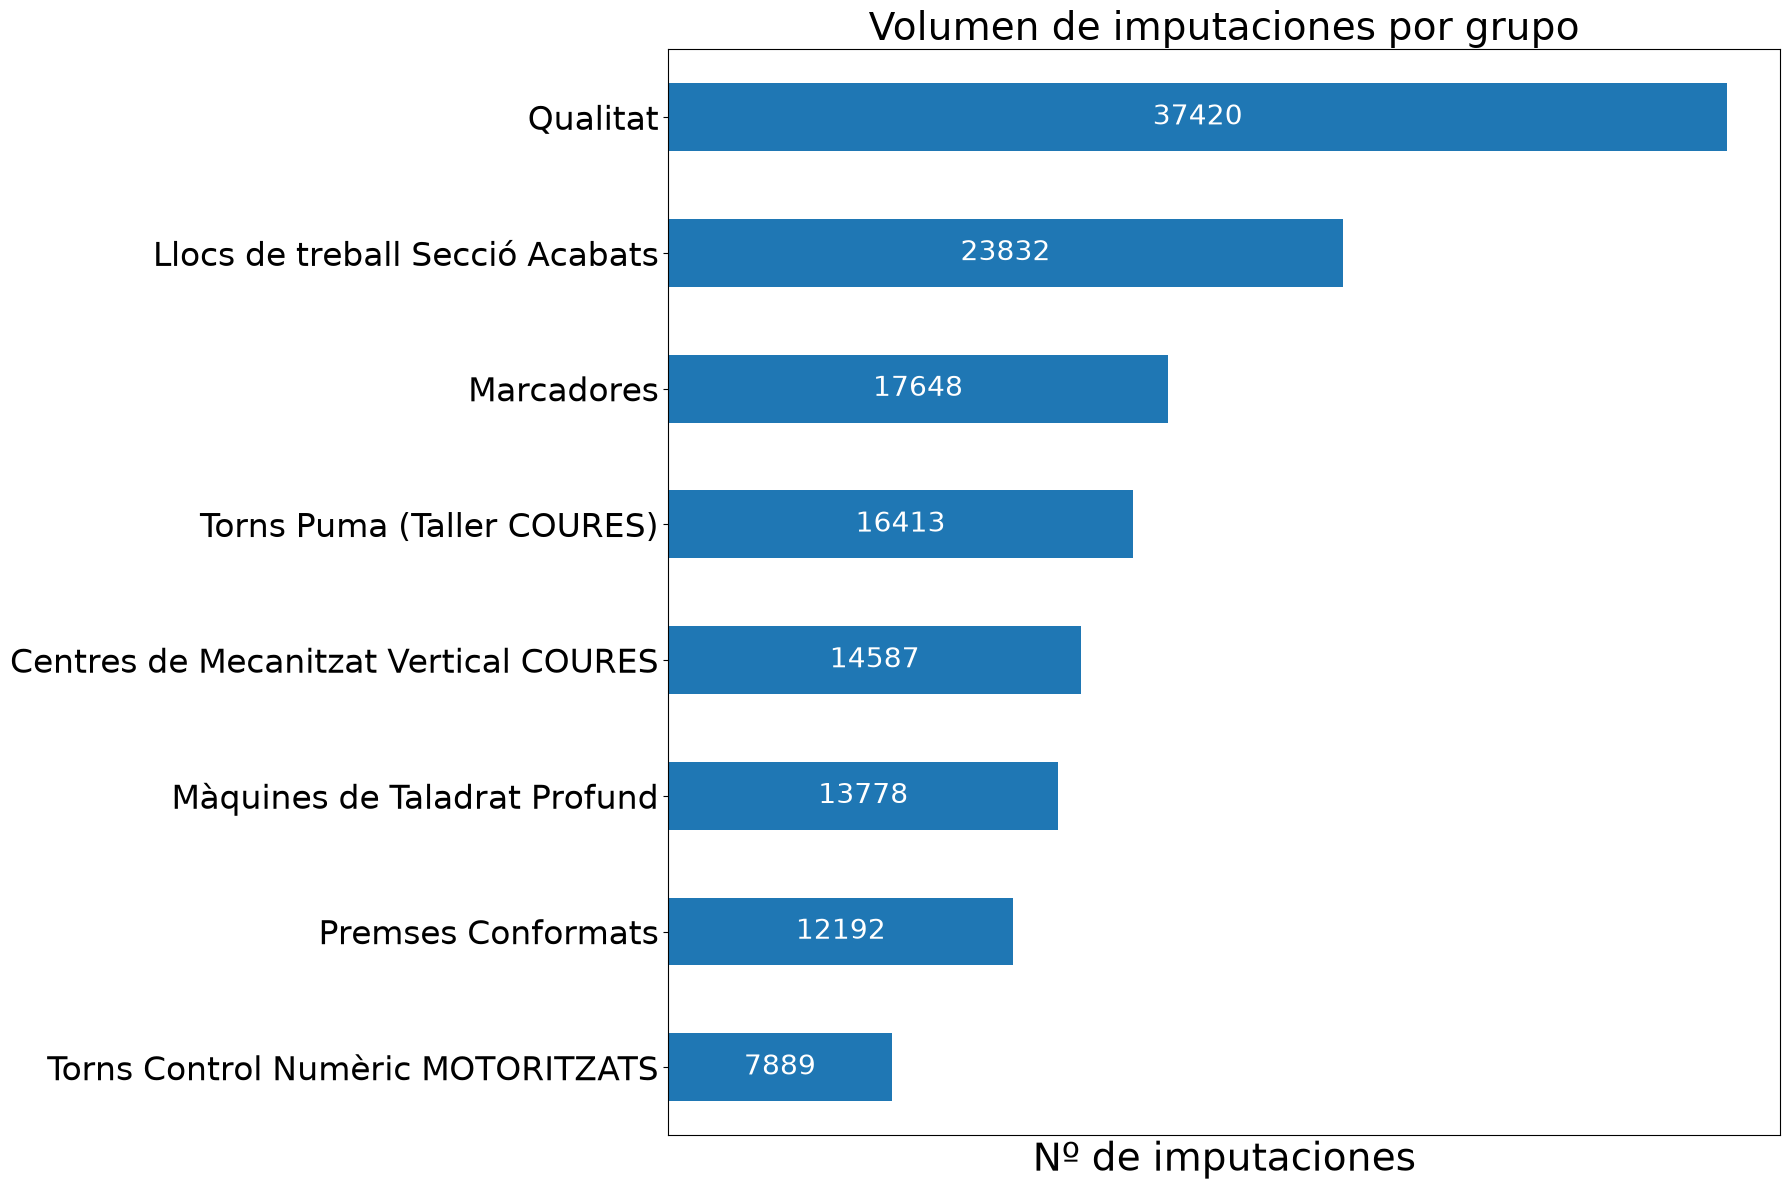

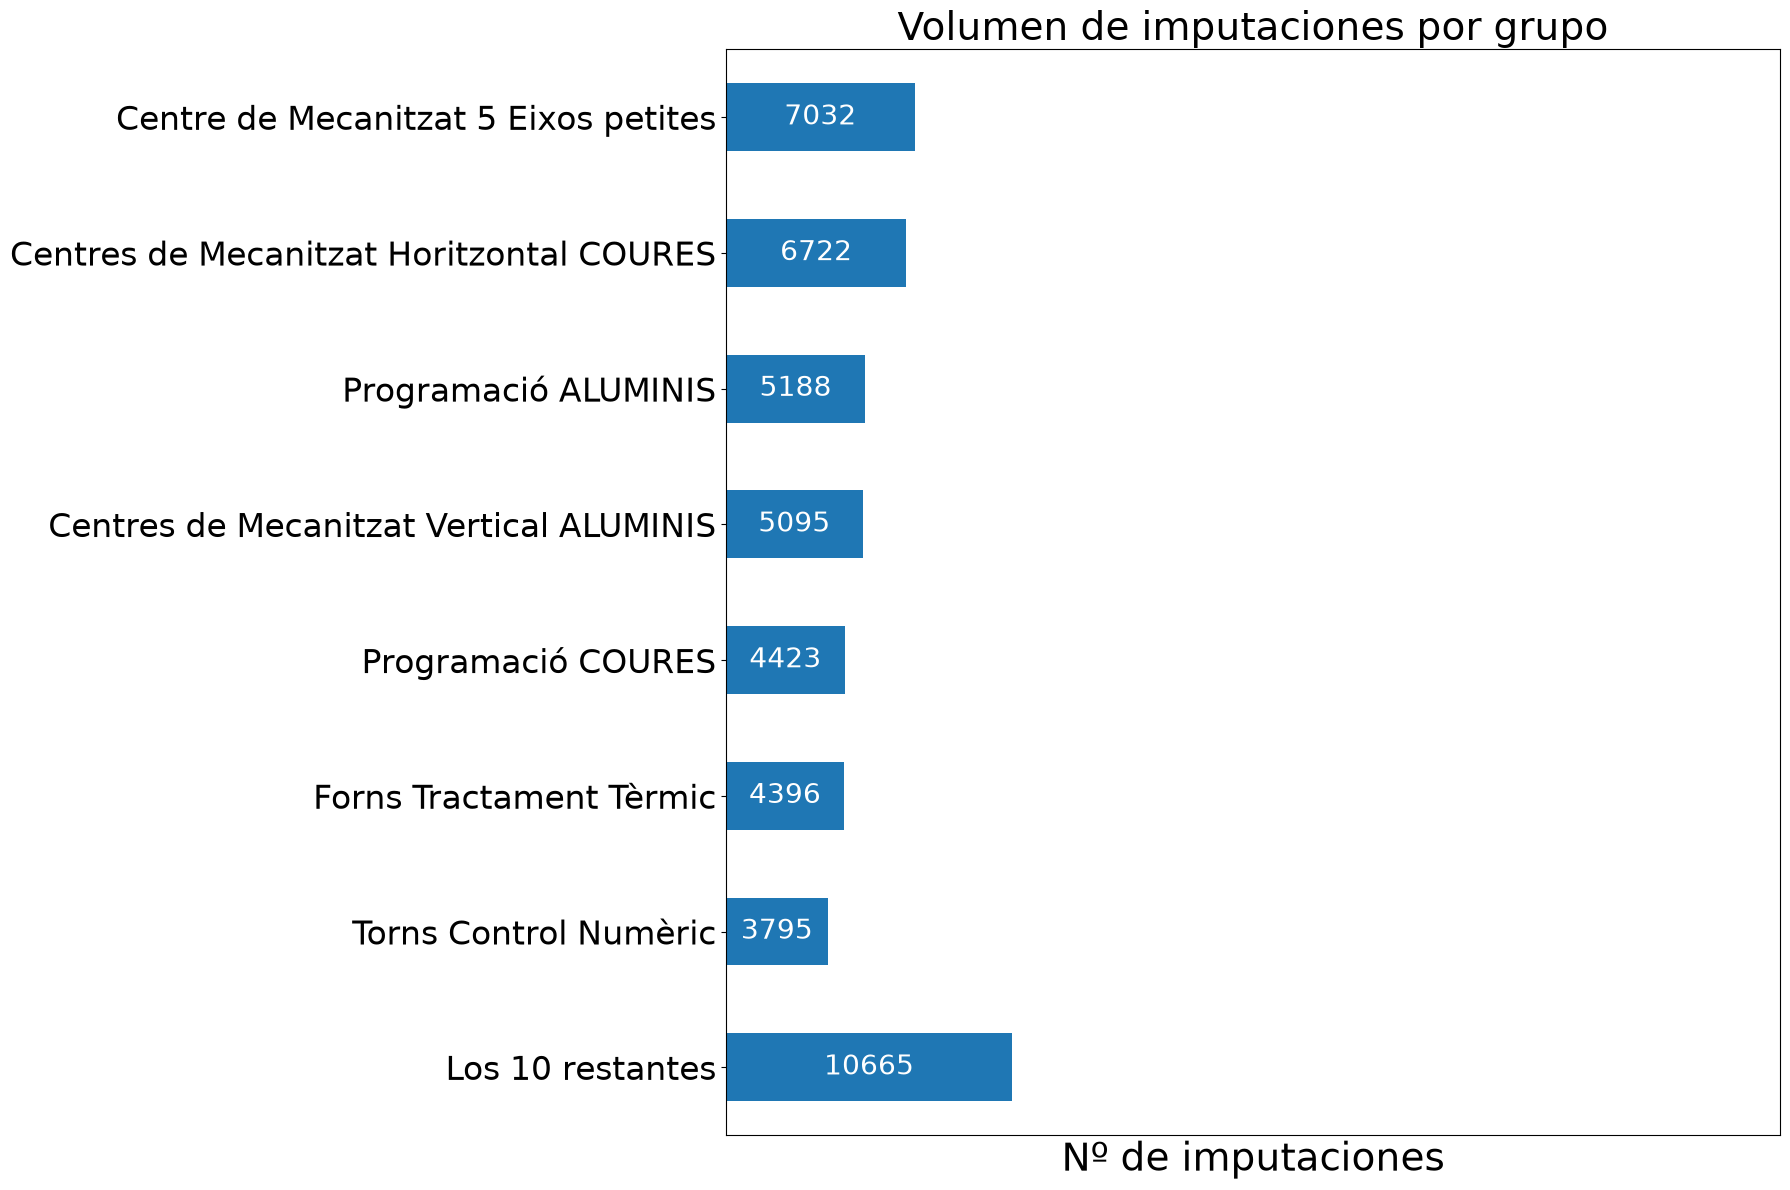

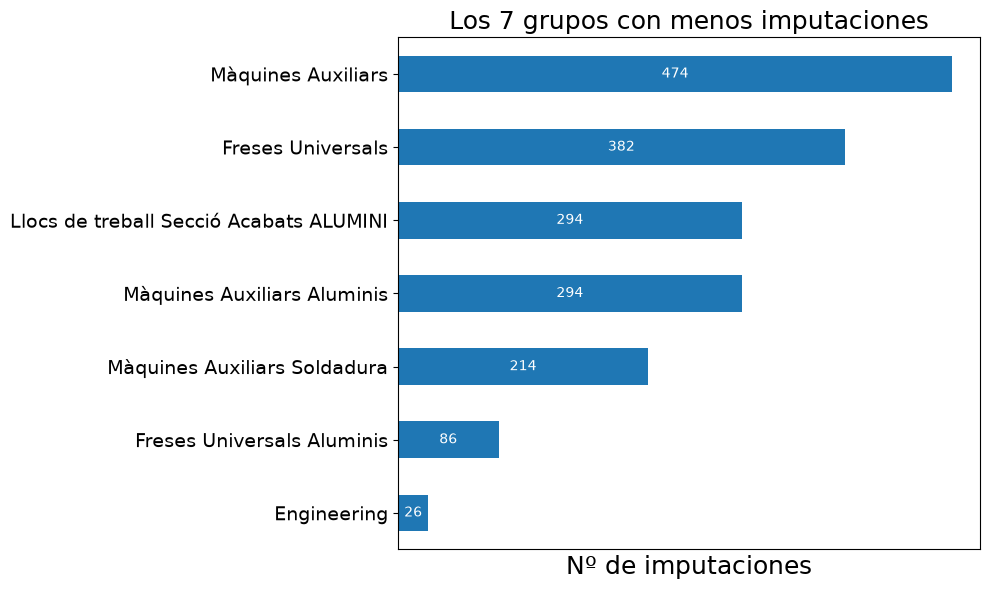

In [8]:
def dibujar(datos, titulo, archivo, x_max=None, grande=True):
    """Barras horizontales con el número de imputaciones de cada grupo."""
    figsize, letra = ((18, 12), 24) if grande else ((10, 6), 14)
    ax = datos.plot(kind="barh", figsize=figsize, fontsize=letra)
    if x_max is not None:
        ax.set_xlim(0, x_max)  # mismo eje X en las dos primeras figuras
    ax.bar_label(ax.containers[0], label_type="center", color="white", fontsize=letra - 4)
    ax.set_ylabel("")
    ax.set_xticks([])
    plt.xlabel("Nº de imputaciones", fontsize=letra + 4)
    plt.title(titulo, fontsize=letra + 4)
    plt.tight_layout()
    plt.savefig(FIGURES / archivo, dpi=200, bbox_inches="tight")
    plt.show()


N_PRIMEROS, N_SIGUIENTES = 8, 7
primeros = uso_grupo.iloc[:N_PRIMEROS]
siguientes = uso_grupo.iloc[N_PRIMEROS:N_PRIMEROS + N_SIGUIENTES]
resto = uso_grupo.iloc[N_PRIMEROS + N_SIGUIENTES:]
x_max = max(primeros.max(), resto.sum()) * 1.05

dibujar(primeros.sort_values(), "Volumen de imputaciones por grupo", "00_imputaciones_grupos_1.png", x_max)

datos = pd.concat([pd.Series({f"Los {len(resto)} restantes": resto.sum()}), siguientes.sort_values()])
dibujar(datos, "Volumen de imputaciones por grupo", "00_imputaciones_grupos_2.png", x_max)

dibujar(uso_grupo.tail(7).sort_values(), "Los 7 grupos con menos imputaciones", "00_imputaciones_grupos_menos.png",
        grande=False)

## 3. Siguientes pasos

La preparación sigue dos ramas que se unen en el notebook 05:

- Rama MES: imputaciones (01) → máquinas y grupos (02) → fases del MES con su tiempo real (03).
- Rama ERP: órdenes de fabricación (04) → fases del ERP con su tiempo teórico, y unión con el MES (05).

Después se añaden los artículos (06), se comprueba la viabilidad (07), se construye la variable objetivo (08) y se
seleccionan las variables (09) antes del modelado (10 a 15).